# 阶段2：杠杆测算（统一口径）

**目的：** 各模块的建议原本使用不同的单位（延误率、延误占比、超额差评等），无法比较。这里把主要杠杆统一换算成"**分析期内可减少的差评数**"（D-034），再附上对应的 GMV（D-037），回答章程的主问题：哪些杠杆的投入产出最高？

**方法：** 静态估计（D-008）。假设其他条件不变，把某个问题改善到基准水平，计算差评会减少多少。各杠杆之间有部分重叠（例如高延误月的延误中也包含卖家超时造成的延误），**不能直接相加**。

**版本：** v2（写报告时更新）。根据 `s2_report_checks.ipynb` 的检验：延误相关的杠杆给出区间（D-036）；"高峰月延误"改为"高延误月承诺校准"（D-035）；多件订单的原因已确认，杠杆改为"完整交付"（D-038）；问题卖家补充多重比较校正后的结果（D-039）。

**数据：** `dws_order_fulfillment`、`dwd_order_reviews`、`ads_m6_seller_tier`；模块3、6 与 `s2_report_checks` 的结论

In [1]:
from olist_utils import run_query, set_style, COLORS
import re
import unicodedata

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom
set_style()

## 1. 转换系数

把"少延误多少单"换算成"少多少差评"，需要知道延误让差评率增加多少。`s2_report_checks` 第 3 节发现这个数字取决于口径（D-036）：
- **上限**：全部评价（模块3 主口径）。收货前写的评价是买家"到了承诺日还没收到货"的真实反应，计入是合理的
- **下限**：只看收货后写的评价

另外，卖家发货超时会让延误风险增加多少（模块3 3.3）。

In [2]:
sql_lift = '''
SELECT AVG(CASE WHEN is_late = 1 THEN is_bad_review END)
     - AVG(CASE WHEN is_late = 0 THEN is_bad_review END)                    AS bad_lift_upper,  -- 全部评价
       AVG(CASE WHEN is_late = 1 AND is_review_before_delivery = 0 THEN is_bad_review END)
     - AVG(CASE WHEN is_late = 0 AND is_review_before_delivery = 0 THEN is_bad_review END) AS bad_lift_lower,  -- 只看收货后的评价
       AVG(CASE WHEN is_seller_late = 1 THEN is_late END)
     - AVG(CASE WHEN is_seller_late = 0 THEN is_late END)                   AS late_lift_ship,  -- 发货超时让延误风险增加多少
       AVG(CASE WHEN is_late = 1 THEN has_review END)                       AS review_rate_late -- 延误订单中有评价的比例
FROM dws_order_fulfillment
'''
lift = run_query(sql_lift).astype(float).iloc[0]
TO_BAD = {"upper": lift["review_rate_late"] * lift["bad_lift_upper"],     # 每少一单延误，少多少差评
          "lower": lift["review_rate_late"] * lift["bad_lift_lower"]}
total_bad = float(run_query("SELECT SUM(is_bad_review) FROM dws_order_fulfillment").iloc[0, 0])
print(f"全部差评 {total_bad:,.0f} 条")
lift.round(4)

全部差评 12,228 条


bad_lift_upper      0.5317
bad_lift_lower      0.1588
late_lift_ship      0.1576
review_rate_late    0.9766
Name: 0, dtype: float64

## 2. 差评来源构成

先看全局：全部差评中，有多少可以归因于已识别的原因。超额差评 = 有评价订单数 ×（该组差评率 − 基准组差评率）。多件订单只看准时送达的订单，与延误不重叠。

In [3]:
late_reviewed = float(run_query("SELECT SUM(has_review) FROM dws_order_fulfillment WHERE is_late = 1").iloc[0, 0])
excess_late = late_reviewed * lift["bad_lift_upper"]
excess_late_lower = late_reviewed * lift["bad_lift_lower"]

sql_multi = '''
SELECT SUM(CASE WHEN n_items > 1 THEN has_review END)                                   AS multi_reviewed,
       SUM(CASE WHEN n_items > 1 THEN is_bad_review END)                                AS multi_bad,
       SUM(CASE WHEN n_items = 1 THEN is_bad_review END) / SUM(CASE WHEN n_items = 1 THEN has_review END) AS single_rate
FROM dws_order_fulfillment
WHERE is_late = 0
'''
mu = run_query(sql_multi).astype(float).iloc[0]
excess_multi = mu["multi_bad"] - mu["multi_reviewed"] * mu["single_rate"]

sources = pd.DataFrame({
    "来源": ["延误", "多件订单", "基线及其他原因"],
    "差评数": [excess_late, excess_multi, total_bad - excess_late - excess_multi],
})
sources["占比"] = sources["差评数"] / total_bad
print(f"可识别来源合计：{(excess_late + excess_multi) / total_bad:.1%}")
print(f"延误的超额差评若只按收货后评价计算：{excess_late_lower:,.0f} 条（{excess_late_lower / total_bad:.1%}）")
sources.round({"差评数": 0, "占比": 3})

可识别来源合计：40.3%
延误的超额差评若只按收货后评价计算：1,013 条（8.3%）


,来源,差评数,占比
0,延误,3391.0,0.277
1,多件订单,1535.0,0.126
2,基线及其他原因,7302.0,0.597


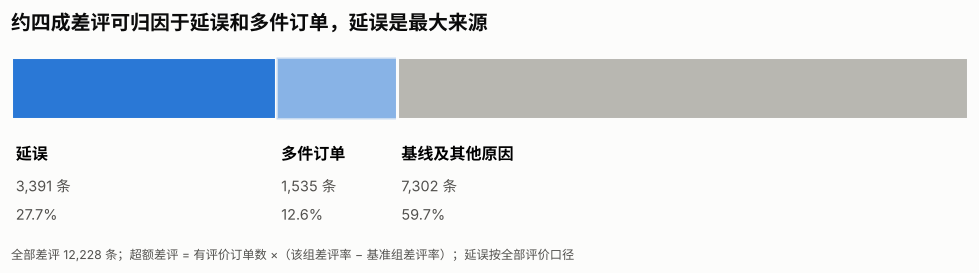

In [4]:
fig, ax = plt.subplots(figsize=(9, 2.6))
colors = [COLORS["blue"], COLORS["blue"], COLORS["gray"]]
alphas = [1.0, 0.55, 1.0]
left = 0.0
for (_, r), c, a in zip(sources.iterrows(), colors, alphas):
    ax.barh(0, r["占比"], left=left, color=c, alpha=a, height=0.5, edgecolor=COLORS["surface"], linewidth=2)
    ax.text(left + 0.005, -0.45, r["来源"], fontsize=10.5, fontweight="bold", va="top")
    ax.text(left + 0.005, -0.72, f"{r['差评数']:,.0f} 条", fontsize=9.5,
            color=COLORS["text_secondary"], va="top")
    ax.text(left + 0.005, -0.95, f"{r['占比']:.1%}", fontsize=9.5,
            color=COLORS["text_secondary"], va="top")
    left += r["占比"]
ax.set_xlim(0, 1)
ax.set_ylim(-1.25, 0.4)
ax.axis("off")
ax.set_title("约四成差评可归因于延误和多件订单，延误是最大来源", loc="left")
ax.text(0.0, -0.08, f"全部差评 {total_bad:,.0f} 条；超额差评 = 有评价订单数 ×（该组差评率 − 基准组差评率）；延误按全部评价口径",
        transform=ax.transAxes, fontsize=8, color=COLORS["text_secondary"])
fig.tight_layout()
fig.savefig("../docs/figures/s2_bad_review_sources.png", dpi=150, bbox_inches="tight")
plt.show()

**读图：** 延误约造成 28% 的差评（只看收货后评价时约 8%），多件订单约 13%，两者合计约四成。其余约六成属于基线水平（准时送达的单件订单也有约 7.5% 的差评率）和尚未识别的原因。

## 3. 各杠杆的测算

每个杠杆给出下限和上限：

| 杠杆 | 测算方法 | 下限 / 上限的区别 |
| --- | --- | --- |
| 高延误月承诺校准 | 承诺随运输时长放宽、保持平常缓冲后，变为按时的延误订单（`s2_report_checks` 4.3）× 转换系数 | 转换系数的下限 / 上限 |
| 卖家发货超时消除 | 超时订单 × 超时增加的延误风险 × 转换系数 + 超时本身的等待效应（模块6 6.3） | 转换系数的下限 / 上限 |
| 头部问题卖家整改 | 问题卖家未延误订单的超额差评（模块6 6.2） | BH 校正后的 32 个 / 主口径的 40 个 |
| 多件订单完整交付 | 多件订单（准时送达）的超额差评（模块3 3.7） | 评论中明确提到收货不完整的差评 / 全部超额差评 |
| RJ 非高延误月治理 | RJ 非高延误月的延误率降到 SP 水平 × 转换系数 | 转换系数的下限 / 上限 |

In [5]:
HIGH_DELAY = ["2017-11", "2018-02", "2018-03"]          # 高延误月（D-032、D-035）
hd_list = ", ".join(f"'{m}'" for m in HIGH_DELAY)

# 杠杆 1：高延误月承诺校准（方法同 s2_report_checks 4.3）
mon = run_query('''
SELECT purchase_month, AVG(delivery_days - delay_days) - AVG(delivery_days) AS buffer
FROM dws_order_fulfillment
WHERE purchase_month >= '2017-05'
GROUP BY purchase_month
''')
mon["buffer"] = mon["buffer"].astype(float)
normal_buffer = mon.loc[~mon["purchase_month"].isin(HIGH_DELAY), "buffer"].median()
ext = mon[mon["purchase_month"].isin(HIGH_DELAY)].assign(extend_days=lambda d: (normal_buffer - d["buffer"]).round())
hd = run_query(f"SELECT purchase_month, delay_days FROM dws_order_fulfillment WHERE purchase_month IN ({hd_list}) AND is_late = 1")
hd = hd.merge(ext[["purchase_month", "extend_days"]], on="purchase_month")
late_avoided_promise = float((hd["delay_days"] <= hd["extend_days"]).sum())

# 杠杆 2：卖家发货超时全部消除
sh = run_query('''
SELECT SUM(is_seller_late)                                                   AS ship_late_orders,
       SUM(CASE WHEN is_seller_late = 1 AND is_late = 0 THEN has_review END) AS ship_late_ontime_reviewed
FROM dws_order_fulfillment
WHERE is_seller_late IS NOT NULL
''').astype(float).iloc[0]
WITHIN_SELLER_EFFECT = 0.0276      # 模块6 6.3：卖家内部对比得到的等待效应
late_avoided_ship = sh["ship_late_orders"] * lift["late_lift_ship"]
bad_ship_wait = sh["ship_late_ontime_reviewed"] * WITHIN_SELLER_EFFECT

# 杠杆 3：头部体验 / 双重问题卖家的未延误差评率降到平台平均；下限只算 BH 校正后仍显著的卖家（s2_report_checks 6.2）
tier = run_query('''
SELECT n_ot_reviewed, n_ot_bad, platform_ot_bad
FROM ads_m6_seller_tier
WHERE is_head = 1 AND problem_type IN ('体验问题', '双重问题')
''').astype(float)
tier["excess"] = tier["n_ot_bad"] - tier["n_ot_reviewed"] * tier["platform_ot_bad"]
all_tested = run_query('''
SELECT is_head, problem_type, n_ot_reviewed, n_ot_bad, platform_ot_bad
FROM ads_m6_seller_tier WHERE problem_type IS NOT NULL
''')
for c in ["n_ot_reviewed", "n_ot_bad", "platform_ot_bad"]:
    all_tested[c] = all_tested[c].astype(float)
p = np.asarray(binom.sf(all_tested["n_ot_bad"] - 1, all_tested["n_ot_reviewed"], all_tested["platform_ot_bad"]))
order = np.argsort(p)
passed = p[order] <= 0.05 * np.arange(1, len(p) + 1) / len(p)
k = passed.nonzero()[0].max() + 1
all_tested["bh"] = False
all_tested.loc[all_tested.index[order[:k]], "bh"] = True
bh_head = all_tested[(all_tested["is_head"] == 1) & all_tested["bh"]]
seller_upper = tier["excess"].sum()
seller_lower = (bh_head["n_ot_bad"] - bh_head["n_ot_reviewed"] * bh_head["platform_ot_bad"]).sum()

# 杠杆 4：多件订单完整交付；下限 = 评论中明确提到收货不完整的多件订单差评（规则同 s2_report_checks 5.3）
cm = run_query('''
SELECT r.review_comment_message AS msg
FROM dws_order_fulfillment f
JOIN dwd_order_reviews r ON f.order_id = r.order_id
WHERE f.is_late = 0 AND f.n_items > 1 AND f.is_bad_review = 1 AND r.has_comment = 1
''')
def normalize(text):
    text = unicodedata.normalize("NFKD", text.lower())
    return "".join(ch for ch in text if not unicodedata.combining(ch))
t = cm["msg"].map(normalize)
incomplete = (t.str.contains(r"\bfalt(?:a|ando|ou|aram|am)\b")
              | (t.str.contains(r"\b(?:apenas|somente|so)\b")
                 & t.str.contains(r"\b(?:recebi|recebemos|veio|vieram|chegou|chegaram|entregaram|entregue|enviaram|mandaram)\b")))
multi_lower = min(float(incomplete.sum()), excess_multi)

# 杠杆 5：RJ 非高延误月的延误率降到 SP 水平
rj = run_query(f'''
SELECT SUM(CASE WHEN customer_state = 'RJ' THEN 1 ELSE 0 END)        AS rj_orders,
       AVG(CASE WHEN customer_state = 'RJ' THEN is_late END)          AS rj_late_rate,
       AVG(CASE WHEN customer_state = 'SP' THEN is_late END)          AS sp_late_rate
FROM dws_order_fulfillment
WHERE purchase_month NOT IN ({hd_list})
''').astype(float).iloc[0]
late_avoided_rj = rj["rj_orders"] * (rj["rj_late_rate"] - rj["sp_late_rate"])

print(f"高延误月承诺校准：{late_avoided_promise:,.0f} 单延误变为按时")
print(f"发货超时消除：减少延误 {late_avoided_ship:,.0f} 单，等待效应 {bad_ship_wait:,.0f} 条差评")
print(f"问题卖家：主口径 40 个 {seller_upper:,.0f} 条，BH 校正后 {len(bh_head)} 个 {seller_lower:,.0f} 条")
print(f"多件订单：超额差评 {excess_multi:,.0f} 条，其中评论明确提到收货不完整 {incomplete.sum():,} 条")
print(f"RJ：减少延误 {late_avoided_rj:,.0f} 单")

高延误月承诺校准：1,223 单延误变为按时
发货超时消除：减少延误 1,344 单，等待效应 184 条差评
问题卖家：主口径 40 个 859 条，BH 校正后 32 个 782 条
多件订单：超额差评 1,535 条，其中评论明确提到收货不完整 1,165 条
RJ：减少延误 293 单


## 4. 杠杆对比与 GMV 换算

**实施难度**按"由谁来做"判定，而不是主观打分：
- **低**：Olist 用现有的规则和运营手段就能做（发货提醒与超时处罚、卖家整改）
- **中**：需要改造 Olist 自己的系统（承诺日期模型、按包裹追踪）
- **高**：依赖外部承运商配合

**GMV 换算**：`s2_report_checks` 1.4 估计每条差评约对应下个月 68 BRL 的 GMV 损失（D-037）。只是短期、量级上的参考。

In [6]:
GMV_PER_BAD = 68          # s2_report_checks 1.4：每条差评对应的下月 GMV 损失（BRL）
total_gmv = float(run_query("SELECT SUM(order_gmv) FROM dws_order_fulfillment").iloc[0, 0])

levers = pd.DataFrame([
    ["多件订单完整交付",               multi_lower,                                              excess_multi,
     "按包裹追踪；全部送达才标记已送达；缺件主动补发", "中"],
    ["高延误月承诺校准",               late_avoided_promise * TO_BAD["lower"],                   late_avoided_promise * TO_BAD["upper"],
     "按运输时长动态放宽承诺日期",                     "中"],
    ["卖家发货超时消除",               late_avoided_ship * TO_BAD["lower"] + bad_ship_wait,      late_avoided_ship * TO_BAD["upper"] + bad_ship_wait,
     "发货截止前提醒；持续超时再处罚",                 "低"],
    ["头部问题卖家整改",               seller_lower,                                             seller_upper,
     "按损害排序，限期整改",                           "低"],
    ["RJ 非高延误月治理",              late_avoided_rj * TO_BAD["lower"],                        late_avoided_rj * TO_BAD["upper"],
     "排查区域承运商",                                 "高"],
], columns=["杠杆", "下限", "上限", "主要手段", "实施难度"])
levers["上限占全部差评"] = levers["上限"] / total_bad
levers["上限对应下月GMV"] = levers["上限"] * GMV_PER_BAD
levers["占总GMV"] = levers["上限对应下月GMV"] / total_gmv
levers = levers.sort_values("上限", ascending=False).reset_index(drop=True)
print(f"全部差评 {total_bad:,.0f} 条；分析期 GMV {total_gmv:,.0f} BRL")
levers.round({"下限": 0, "上限": 0, "上限占全部差评": 3, "上限对应下月GMV": 0, "占总GMV": 4})

全部差评 12,228 条；分析期 GMV 13,179,778 BRL


,杠杆,下限,上限,主要手段,实施难度,上限占全部差评,上限对应下月GMV,占总GMV
0,多件订单完整交付,1165.0,1535.0,按包裹追踪；全部送达才标记已送达；缺件主动补发,中,0.126,104359.0,0.0079
1,卖家发货超时消除,393.0,882.0,发货截止前提醒；持续超时再处罚,低,0.072,59986.0,0.0046
2,头部问题卖家整改,782.0,859.0,按损害排序，限期整改,低,0.070,58417.0,0.0044
3,高延误月承诺校准,190.0,635.0,按运输时长动态放宽承诺日期,中,0.052,43184.0,0.0033
4,RJ 非高延误月治理,45.0,152.0,排查区域承运商,高,0.012,10358.0,0.0008


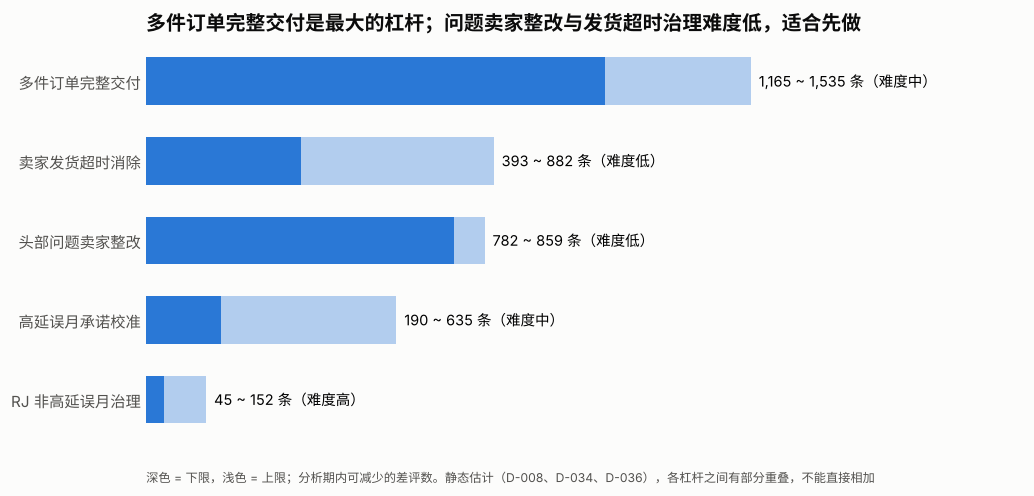

In [7]:
fig, ax = plt.subplots(figsize=(9.5, 4.6))
y = np.arange(len(levers))[::-1]
ax.barh(y, levers["上限"], color=COLORS["blue"], alpha=0.35, height=0.6)
ax.barh(y, levers["下限"], color=COLORS["blue"], height=0.6)
for yi, r in zip(y, levers.itertuples()):
    ax.text(r.上限 + 20, yi, f"{r.下限:,.0f} ~ {r.上限:,.0f} 条（难度{r.实施难度}）", va="center", fontsize=9.5)
ax.set_yticks(y)
ax.set_yticklabels(levers["杠杆"])
ax.set_xlim(0, levers["上限"].max() * 1.45)
ax.set_xticks([])
ax.grid(False)
for s in ["left", "bottom"]:
    ax.spines[s].set_visible(False)
ax.set_title("多件订单完整交付是最大的杠杆；问题卖家整改与发货超时治理难度低，适合先做", loc="left")
ax.text(0.0, -0.1, "深色 = 下限，浅色 = 上限；分析期内可减少的差评数。静态估计（D-008、D-034、D-036），各杠杆之间有部分重叠，不能直接相加",
        transform=ax.transAxes, fontsize=8, color=COLORS["text_secondary"])
fig.tight_layout()
fig.savefig("../docs/figures/s2_levers.png", dpi=150, bbox_inches="tight")
plt.show()

**结论：**
- **多件订单完整交付**是最大的杠杆（约 1,165~1,535 条）：即使只算评论中明确提到收货不完整的差评，也超过一千条。它需要改造订单与物流追踪系统，难度中等
- **头部问题卖家整改**（约 782~859 条）和**卖家发货超时消除**（约 393~882 条）难度低，可以作为短期动作；其中问题卖家整改的区间最窄，结果最确定
- **高延误月承诺校准**（约 190~635 条）比原来"高峰月延误率降到平常水平"的估计（约 1,155 条）小得多：放宽承诺只能让约四成的延误变为按时，而且只看收货后评价时效果更小。但它是平台可以直接控制的手段，且成本低于增加运力
- **RJ 非高延误月治理**收益最小（约 45~152 条），且依赖外部承运商，优先级最低
- 换算成 GMV，单个杠杆上限约为分析期 GMV 的 0.1%~0.8%（短期、下个月的影响）。体验杠杆的价值主要在于**保护**口碑和卖家销量，而不是带来新的 GMV 增长